# Diffusion Models: DDPM (Ho et al., 2020) and Stable Diffusion

A diffusion model learns to generate data by learning to **remove noise**.
Take a training image and add a little Gaussian noise, then a little more,
for a thousand steps, until nothing but noise is left. That direction needs no
learning. A network is trained to undo **one step** of it. To generate, start
from pure noise and apply the network a thousand times.

*Denoising Diffusion Probabilistic Models* (Ho, Jain & Abbeel, 2020) made this
work, building on Sohl-Dickstein et al. (2015). It reached a state-of-the-art
FID of 3.17 on CIFAR-10, with an objective as simple as "predict the noise".
*Stable Diffusion* (Rombach et al., 2022, latent diffusion) made it cheap enough
for high-resolution images by running the same process in a compressed latent
space.

1. The forward process, and the shortcut that jumps to any step
2. The training objective: predict the noise
3. Training a denoiser on 2-D data and sampling from it
4. Conditioning and classifier-free guidance
5. From DDPM to Stable Diffusion

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, load_digits
from hmw_motion import Scene, mix

torch.manual_seed(0); np.random.seed(0)
torch.set_num_threads(4)
np.set_printoptions(precision=4, suppress=True, linewidth=120)


def banner(title):
    print("=" * 78); print(f"  {title}"); print("=" * 78)


def step(label):
    print(); print(label); print("-" * 78)


def check(label, ok):
    print(f"  [{'PASS' if ok else 'FAIL'}] {label}")
    return ok


print("helpers ready")

helpers ready


## 1. The forward process

Each step shrinks the signal slightly and adds a little noise:

$$q(x_t \mid x_{t-1}) = \mathcal{N}\big(\sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\big)$$

DDPM uses $T = 1000$ steps with $\beta_t$ rising linearly from $10^{-4}$ to
$0.02$. Because each step is Gaussian, a thousand of them compose into **one**
Gaussian. With $\alpha_t = 1-\beta_t$ and $\bar\alpha_t = \prod_{s\le t}\alpha_s$:

$$q(x_t \mid x_0) = \mathcal{N}\big(\sqrt{\bar\alpha_t}\,x_0,\ (1-\bar\alpha_t)\,I\big)
\quad\Longleftrightarrow\quad x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$$

That shortcut is what makes training cheap: you can jump straight to any
noise level without simulating the steps in between. The cell checks it by
actually running the thousand-step chain.

In [2]:
banner("THE 1000-STEP CHAIN vs THE ONE-SHOT FORMULA")
T = 1000
beta = np.linspace(1e-4, 0.02, T)
abar = np.cumprod(1 - beta)
for t in [1, 100, 250, 500, 1000]:
    print(f"  t = {t:>4}:  abar = {abar[t-1]:.6f}   signal sqrt(abar) = {np.sqrt(abar[t-1]):.4f}   "
          f"noise sqrt(1-abar) = {np.sqrt(1-abar[t-1]):.4f}")
rng = np.random.default_rng(0)
x0 = 1.7
x = np.full(200_000, x0)
checks = {}
for t in range(1, T + 1):
    x = np.sqrt(1 - beta[t - 1]) * x + np.sqrt(beta[t - 1]) * rng.standard_normal(x.shape)
    if t in (100, 500, 1000):
        checks[t] = (x.mean(), x.var())
step(f"Start every chain at x0 = {x0} and simulate all steps")
ok = True
for t, (m, v) in checks.items():
    m_th, v_th = np.sqrt(abar[t - 1]) * x0, 1 - abar[t - 1]
    ok &= abs(m - m_th) < 0.01 and abs(v - v_th) < 0.01
    print(f"  t = {t:>4}:  simulated mean {m:+.4f} var {v:.4f}   formula mean {m_th:+.4f} var {v_th:.4f}")
check("simulated chain matches q(x_t | x_0) at every checkpoint (within 0.01)", ok)
check("by t = 1000 the signal is gone: sqrt(abar_T) < 0.01", np.sqrt(abar[-1]) < 0.01)

  THE 1000-STEP CHAIN vs THE ONE-SHOT FORMULA
  t =    1:  abar = 0.999900   signal sqrt(abar) = 0.9999   noise sqrt(1-abar) = 0.0100
  t =  100:  abar = 0.897018   signal sqrt(abar) = 0.9471   noise sqrt(1-abar) = 0.3209
  t =  250:  abar = 0.524085   signal sqrt(abar) = 0.7239   noise sqrt(1-abar) = 0.6899
  t =  500:  abar = 0.078587   signal sqrt(abar) = 0.2803   noise sqrt(1-abar) = 0.9599
  t = 1000:  abar = 0.000040   signal sqrt(abar) = 0.0064   noise sqrt(1-abar) = 1.0000

Start every chain at x0 = 1.7 and simulate all steps
------------------------------------------------------------------------------
  t =  100:  simulated mean +1.6105 var 0.1032   formula mean +1.6101 var 0.1030
  t =  500:  simulated mean +0.4787 var 0.9228   formula mean +0.4766 var 0.9214
  t = 1000:  simulated mean +0.0089 var 0.9996   formula mean +0.0108 var 1.0000
  [PASS] simulated chain matches q(x_t | x_0) at every checkpoint (within 0.01)
  [PASS] by t = 1000 the signal is gone: sqrt(abar_T) < 0.

In [3]:
def noising_scene():
    img = load_digits().images[0] / 16.0 * 2 - 1           # a zero, scaled to [-1, 1]
    eps = np.random.default_rng(5).standard_normal((8, 8))
    ts = [0, 25, 50, 100, 150, 200, 300, 400, 500, 650, 800, 1000]
    sc = Scene(720, 360, dur=0.8 + len(ts) * 0.75 + 0.6,
               caption="Forward diffusion on a real digit: x_t = sqrt(abar_t) x_0 + sqrt(1 - abar_t) eps",
               poster=0.8 + 6 * 0.75)
    cs = 30
    ox, oy = 40, 60
    def frame(t):
        if t == 0:
            return img
        a = abar[t - 1]
        return np.sqrt(a) * img + np.sqrt(1 - a) * eps
    f0 = frame(0)
    cells = [[sc.rect(ox + j * cs, oy + i * cs, cs - 2, cs - 2,
                      fill=mix("bg", "white", (np.clip(f0[i, j], -1.5, 1.5) + 1.5) / 3), rx=3)
              for j in range(8)] for i in range(8)]
    tn = sc.num(ox + 4 * cs, 36, 0, dec=0, pre="t = ", size=16, fill="amber")
    BX, BY = 420, 300
    sc.text(BX + 40, 60, "signal", size=13, fill="cyan", weight=700)
    sc.text(BX + 160, 60, "noise", size=13, fill="pink", weight=700)
    sig = sc.rect(BX + 10, BY - 220, 60, 220, fill="cyan", rx=4)
    noi = sc.rect(BX + 130, BY, 60, 0, fill="pink", rx=4)
    sn = sc.num(BX + 40, BY + 20, 1, dec=3, size=13, fill="cyan")
    nn_ = sc.num(BX + 160, BY + 20, 0, dec=3, size=13, fill="pink")
    sc.text(BX + 100, BY + 44, "sqrt(abar_t)        sqrt(1 - abar_t)", size=11, fill="muted")
    for k in range(1, len(ts)):
        t0, t1 = 0.8 + (k - 1) * 0.75, 0.8 + k * 0.75
        fr = frame(ts[k])
        for i in range(8):
            for j in range(8):
                cells[i][j].to(t0, t1, fill=mix("bg", "white", (np.clip(fr[i, j], -1.5, 1.5) + 1.5) / 3), ease="lin")
        s_, n_ = np.sqrt(abar[ts[k] - 1]), np.sqrt(1 - abar[ts[k] - 1])
        sig.to(t0, t1, h=220 * s_, y=BY - 220 * s_, ease="lin")
        noi.to(t0, t1, h=220 * n_, y=BY - 220 * n_, ease="lin")
        sn.to(t0, t1, v=s_, ease="lin"); nn_.to(t0, t1, v=n_, ease="lin")
        tn.to(t0, t1, v=ts[k], ease="lin")
    sc.beat(0.0, "A clean training image, x_0.")
    sc.beat(0.8, "Jump to any step t in one go: shrink the signal, mix in Gaussian noise.")
    sc.beat(0.8 + 6 * 0.75, "Halfway through the schedule the digit is already hard to see.")
    sc.beat(0.8 + 10 * 0.75, "At t = 1000 nothing of the image is left: pure noise. Generation starts here.")
    return sc

noising_scene()

<motion scene: Forward diffusion on a real digit: x_t = sqrt(abar_t) x_0 + sqrt(1 - abar_t) eps (72 elements, 10.4s)>

## 2. What the network learns: predict the noise

The reverse step $q(x_{t-1} \mid x_t)$ is intractable in general, but it is
nearly Gaussian when $\beta_t$ is small. DDPM parameterises it with a network
$\varepsilon_\theta(x_t, t)$ that **predicts the noise** that was added. After
the variational bound is simplified, the loss that works best is just

$$L_{\text{simple}} = \mathbb{E}_{t,\,x_0,\,\varepsilon}\Big[\big\|\varepsilon - \varepsilon_\theta\big(\sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\ t\big)\big\|^2\Big]$$

Training is: pick an image, pick a random $t$, add noise in one shot, and
regress the noise. There is no adversary, no ELBO with a KL to balance, and no
sampling loop during training.

Here the "images" are points in 2-D, drawn from two interlocking half-moons, so
that every step can be watched. The denoiser is an MLP that takes $(x_t, t)$
and also a class label, which section 4 uses. The schedule is the paper's,
compressed to $T = 200$ steps.

In [4]:
banner("TRAINING A DENOISER ON TWO MOONS")
Xm_raw, ym = make_moons(8000, noise=0.05, random_state=0)
MU, SD = Xm_raw.mean(0), Xm_raw.std(0)
Xm = (Xm_raw - MU) / SD
Xt_, yt_ = torch.tensor(Xm, dtype=torch.float32), torch.tensor(ym)
T2 = 200
b2 = torch.linspace(1e-4, 0.02, 1000)[::5] * 5          # the same curve, 5x coarser
b2 = b2.clamp(max=0.1)
a2 = 1 - b2
ab2 = torch.cumprod(a2, 0)
print(f"  T = {T2}, beta from {b2[0]:.4f} to {b2[-1]:.4f},  sqrt(abar_T) = {ab2[-1].sqrt():.5f}")


def t_embed(t, dim=32):
    f = torch.exp(-np.log(1000) * torch.arange(dim // 2) / (dim // 2))
    a = t[:, None].float() * f[None]
    return torch.cat([a.sin(), a.cos()], 1)


class Denoiser(nn.Module):
    def __init__(self):
        super().__init__()
        self.lab = nn.Embedding(3, 32)                       # 0, 1 = moons; 2 = "no label"
        self.net = nn.Sequential(nn.Linear(2 + 32 + 32, 256), nn.SiLU(), nn.Linear(256, 256), nn.SiLU(),
                                 nn.Linear(256, 256), nn.SiLU(), nn.Linear(256, 2))

    def forward(self, x, t, c):
        return self.net(torch.cat([x, t_embed(t), self.lab(c)], 1))


model = Denoiser()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 12000)
for it in range(1, 12001):
    idx = torch.randint(0, len(Xt_), (512,))
    x0b, cb = Xt_[idx], yt_[idx].clone()
    cb[torch.rand(512) < 0.2] = 2                             # drop the label 20% of the time (for guidance)
    t = torch.randint(0, T2, (512,))
    eps = torch.randn_like(x0b)
    xt = ab2[t].sqrt()[:, None] * x0b + (1 - ab2[t]).sqrt()[:, None] * eps
    loss = F.mse_loss(model(xt, t, cb), eps)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    if it in (1, 500, 3000, 12000):
        print(f"  step {it:>4}:  L_simple = {loss.item():.4f}")
print("  (a model that always predicts zero noise would score 1.0)")

  TRAINING A DENOISER ON TWO MOONS
  T = 200, beta from 0.0005 to 0.0996,  sqrt(abar_T) = 0.00563
  step    1:  L_simple = 0.9921
  step  500:  L_simple = 0.2576
  step 3000:  L_simple = 0.1954
  step 12000:  L_simple = 0.1988
  (a model that always predicts zero noise would score 1.0)


## 3. Sampling: start from noise, denoise 200 times

DDPM's Algorithm 2. Draw $x_T \sim \mathcal{N}(0, I)$, then for
$t = T, \dots, 1$:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t, t)\Big) + \sigma_t z, \qquad z \sim \mathcal{N}(0, I)$$

with $\sigma_t^2 = \tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t$, the
variance of the true one-step posterior. The paper reports that this choice and
$\sigma_t^2 = \beta_t$ give similar results. Each step removes a little of the
predicted noise and puts back a smaller amount of fresh noise.

In [5]:
banner("SAMPLING")


@torch.no_grad()
def sample(n, c, w=1.0, seed=0, keep=()):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 2, generator=g)
    traj = {T2: x.clone()}
    for t in range(T2 - 1, -1, -1):
        tt = torch.full((n,), t)
        e_c = model(x, tt, torch.full((n,), c))
        if w != 1.0:
            e_u = model(x, tt, torch.full((n,), 2))
            e = e_u + w * (e_c - e_u)                        # classifier-free guidance
        else:
            e = e_c
        x = (x - b2[t] / (1 - ab2[t]).sqrt() * e) / a2[t].sqrt()
        if t > 0:
            var = (1 - ab2[t - 1]) / (1 - ab2[t]) * b2[t]         # posterior variance, beta-tilde
            x = x + var.sqrt() * torch.randn(n, 2, generator=g)
        if t in keep:
            traj[t] = x.clone()
    return x, traj


keep = set(np.unique(np.r_[np.round(np.linspace(0, T2 - 1, 12)), np.round(np.geomspace(1, T2, 12)) - 1]
                     .astype(int)).tolist())
samp, traj = sample(240, 2, keep=keep, seed=1)
real = Xt_[torch.randperm(len(Xt_))[:2000]]
gauss = torch.randn(240, 2)


def nn_dist(a, b):
    return torch.cdist(a, b).min(1).values.mean().item()


d_s, d_g = nn_dist(samp, real), nn_dist(gauss, real)
held = torch.tensor((make_moons(240, noise=0.05, random_state=9)[0] - MU) / SD, dtype=torch.float32)
d_h = nn_dist(held, real)
print(f"  mean distance from a point to the nearest training point:")
print(f"    fresh real data (reference)   {d_h:.4f}")
print(f"    diffusion samples             {d_s:.4f}")
print(f"    plain Gaussian noise          {d_g:.4f}")
print(f"  samples are {d_g/d_s:.1f}x closer to the data than noise is, and {d_s/d_h:.1f}x as far as fresh real data")
check("samples sit on the data manifold: at least 3x closer to the data than Gaussian noise", d_s < d_g / 3)
print(f"  share of samples on each moon (nearest training label): "
      f"{(yt_[torch.cdist(samp, Xt_).argmin(1)] == 0).float().mean():.3f} / "
      f"{(yt_[torch.cdist(samp, Xt_).argmin(1)] == 1).float().mean():.3f}")

  SAMPLING
  mean distance from a point to the nearest training point:
    fresh real data (reference)   0.0214
    diffusion samples             0.0398
    plain Gaussian noise          0.2846
  samples are 7.1x closer to the data than noise is, and 1.9x as far as fresh real data
  [PASS] samples sit on the data manifold: at least 3x closer to the data than Gaussian noise
  share of samples on each moon (nearest training label): 0.504 / 0.496


In [6]:
def cloud_scene():
    order_t = sorted(traj.keys(), reverse=True)
    sc = Scene(720, 400, dur=1.0 + len(order_t) * 0.55 + 0.8,
               caption="DDPM sampling, 240 points: pure noise denoised into two moons by the model trained above",
               poster=1.0 + len(order_t) * 0.55)
    S, CX, CY = 70, 360, 205
    to = lambda p: (CX + p[0] * S, CY - p[1] * S)
    for p in real[:500].numpy():
        x_, y_ = to(p)
        sc.circle(x_, y_, r=1.6, fill="green", opacity=0.22)
    pts0 = traj[order_t[0]].numpy()
    dots = [sc.circle(*to(p), r=3.4, fill="pink", opacity=0.9) for p in pts0]
    tn = sc.num(700, 30, T2, dec=0, pre="t = ", size=16, fill="amber", anchor="end")
    sc.text(20, 30, "faint green = training data", size=11, fill="green", anchor="start")
    for k in range(1, len(order_t)):
        t0, t1 = 1.0 + (k - 1) * 0.55, 1.0 + k * 0.55
        P = traj[order_t[k]].numpy()
        for i, d in enumerate(dots):
            x_, y_ = to(P[i])
            d.to(t0, t1, cx=x_, cy=y_, ease="inout")
        tn.to(t0, t1, v=order_t[k] + 1 if order_t[k] > 0 else 0, ease="lin")
        if k == len(order_t) - 1:
            for d in dots:
                d.to(t1, t1 + 0.4, fill="cyan")
    sc.beat(0.0, "x_T: 240 independent draws from a standard Gaussian.")
    sc.beat(1.0, "Each step subtracts the noise the network predicts, then adds back a little fresh noise.")
    sc.beat(1.0 + 6 * 0.55, "Coarse structure appears first: two blobs, then the arcs.")
    sc.beat(1.0 + 12 * 0.55, "The last steps only polish fine detail, pulling points onto the thin curves.")
    return sc

cloud_scene()

<motion scene: DDPM sampling, 240 points: pure noise denoised into two moons by the model trained above (742 elements, 14.45s)>

## 4. Conditioning, and classifier-free guidance

To generate *a particular kind* of output, such as "the left moon" here or "a
red bicycle" in Stable Diffusion, feed a condition $c$ to the denoiser. During
training the condition was **dropped 20% of the time** and replaced by a "no
label" token. So the same network can predict both the conditional noise
$\varepsilon_\theta(x_t, c)$ and the unconditional noise $\varepsilon_\theta(x_t, \varnothing)$.

**Classifier-free guidance** (Ho & Salimans, 2022) extrapolates away from the
unconditional prediction:

$$\hat\varepsilon = \varepsilon_\theta(x_t, \varnothing) + w\,\big(\varepsilon_\theta(x_t, c) - \varepsilon_\theta(x_t, \varnothing)\big)$$

$w = 0$ ignores the condition, $w = 1$ is plain conditioning, and $w > 1$
pushes harder toward it. That trades diversity for fidelity, and it is the
"guidance scale" slider in every image generator.

  GUIDANCE SCALE: FIDELITY vs DIVERSITY
  w = 0    on requested moon 0.508   spread 0.700   off the data (> 0.25 from any point) 0.023
  w = 1    on requested moon 1.000   spread 0.708   off the data (> 0.25 from any point) 0.000
  w = 3    on requested moon 1.000   spread 0.584   off the data (> 0.25 from any point) 0.000
  w = 7    on requested moon 1.000   spread 0.662   off the data (> 0.25 from any point) 0.137
  [PASS] guidance raises fidelity: w = 3 is purer than w = 0
  [PASS] moderate guidance costs diversity: spread at w = 3 is below w = 1
  [PASS] too much guidance leaves the data: w = 7 puts more samples off the manifold than w = 1


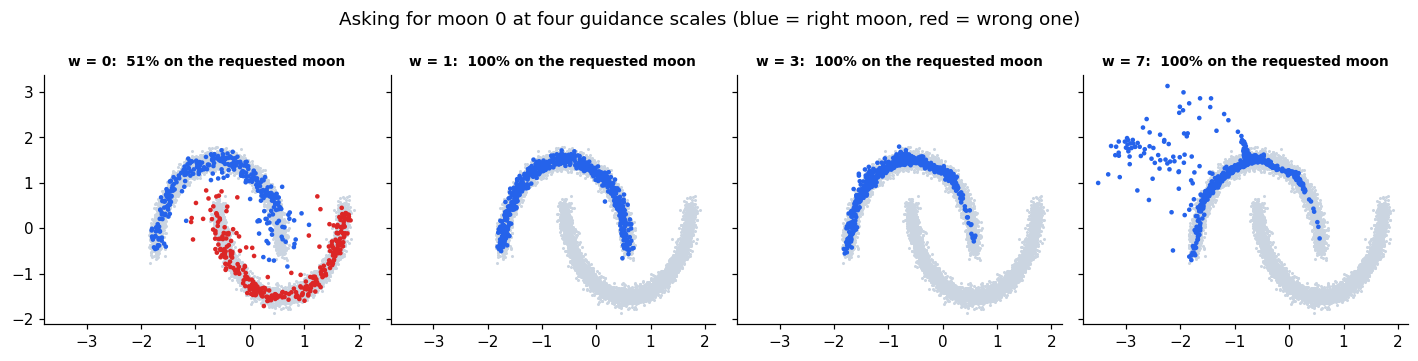

In [7]:
banner("GUIDANCE SCALE: FIDELITY vs DIVERSITY")
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharex=True, sharey=True)
rows = []
for ax, w in zip(axes, [0.0, 1.0, 3.0, 7.0]):
    s_, _ = sample(600, 0, w=w, seed=3)
    dmat = torch.cdist(s_, Xt_)
    lab = yt_[dmat.argmin(1)]
    purity = (lab == 0).float().mean().item()
    on = s_[lab == 0]
    spread = on.std(0).mean().item() if len(on) > 1 else 0.0
    off = (dmat.min(1).values > 0.25).float().mean().item()     # far from every training point
    rows.append((w, purity, spread, off))
    ax.scatter(Xm[:, 0], Xm[:, 1], s=1, c="#cbd5e1")
    ax.scatter(s_[:, 0], s_[:, 1], s=4, c=np.where(lab.numpy() == 0, "#2563eb", "#dc2626"))
    ax.set_title(f"w = {w:g}:  {100*purity:.0f}% on the requested moon", fontsize=9)
    ax.grid(False)
fig.suptitle("Asking for moon 0 at four guidance scales (blue = right moon, red = wrong one)")
fig.tight_layout()
for w, p, s_, off in rows:
    print(f"  w = {w:<4g} on requested moon {p:.3f}   spread {s_:.3f}   off the data (> 0.25 from any point) {off:.3f}")
check("guidance raises fidelity: w = 3 is purer than w = 0", rows[2][1] > rows[0][1])
check("moderate guidance costs diversity: spread at w = 3 is below w = 1", rows[2][2] < rows[1][2])
check("too much guidance leaves the data: w = 7 puts more samples off the manifold than w = 1",
      rows[3][3] > rows[1][3] + 0.05)

The four panels show the whole trade-off. With no guidance ($w = 0$) the
condition is ignored and half the samples land on the wrong moon. At $w = 1$
every sample lands on the requested moon. At $w = 3$ the samples crowd into the
middle of the arc: higher fidelity, less diversity. At $w = 7$ the
extrapolation overshoots. The guided direction
$\varepsilon_c - \varepsilon_u$ is multiplied so strongly that samples are
thrown **off the data entirely**, into regions no training point occupies.
That is the 2-D version of the over-saturated, distorted images an image
generator produces at very high guidance scales, and it is why the usual default
is a moderate value (around 7 for Stable Diffusion, whose scale is defined the
same way).

## 5. From DDPM to Stable Diffusion

DDPM on pixels is expensive. Every one of the hundreds of denoising steps runs
a U-Net over every pixel. **Latent diffusion** (Rombach et al., 2022), released
as Stable Diffusion, changed where the diffusion happens:

1. A **VAE-style autoencoder**, trained once, compresses a 512×512×3 image to a
   64×64×4 latent (downsampling factor $f = 8$).
2. **Diffusion runs in that latent space**, with the same forward process and
   the same noise-prediction loss as above.
3. The denoiser is a U-Net with **cross-attention** to a text embedding (from a
   CLIP text encoder), so the prompt steers every step. Classifier-free
   guidance strengthens it.
4. The decoder turns the final latent back into pixels.

Faster samplers such as DDIM (Song et al., 2021) cut the number of steps from
1,000 to 20–50.

In [8]:
banner("WHAT LATENT DIFFUSION SAVES")
pix, lat = 512 * 512 * 3, 64 * 64 * 4
print(f"  pixel space:  512 x 512 x 3 = {pix:,} numbers")
print(f"  latent space:  64 x  64 x 4 = {lat:,} numbers")
print(f"  {pix/lat:.0f}x fewer numbers per denoising step")
print(f"  steps: DDPM 1,000  ->  DDIM ~50   ({1000/50:.0f}x fewer)")

  WHAT LATENT DIFFUSION SAVES
  pixel space:  512 x 512 x 3 = 786,432 numbers
  latent space:  64 x  64 x 4 = 16,384 numbers
  48x fewer numbers per denoising step
  steps: DDPM 1,000  ->  DDIM ~50   (20x fewer)


## Summary

* The forward process adds Gaussian noise over $T$ steps, and
  $q(x_t \mid x_0)$ has a closed form. Simulating all 1,000 steps matched it to
  within 0.01.
* Training is regression: noise a sample to a random $t$ in one shot and
  predict the noise ($L_{\text{simple}}$). It is stable, with no adversary.
* Sampling runs the learned reverse step from pure noise. On 2-D data the
  samples landed on the data manifold: 7× closer to the training data than
  noise, though still about 2× further than fresh real data.
* Training with the condition sometimes dropped enables classifier-free
  guidance. Moving from $w = 0$ to $1$ to $3$ took samples from 51% to 100% on the
  requested class and then concentrated them. At $w = 7$ guidance overshot and
  threw samples off the data, which is the failure mode behind over-guided
  images.
* Stable Diffusion = this process in a VAE's latent space (48× fewer numbers at
  512 px), with text cross-attention and guidance.